### 17. Experiment 1: Tokenization Analysis

In [5]:
import platform, subprocess

try:
    import torch
except ImportError:
    torch = None

print("Python :", platform.python_version())
if torch is None:
    DEVICE = "cpu"
    print("PyTorch: chưa cài")
else:
    print("PyTorch:", torch.__version__)
    if torch.cuda.is_available():
        DEVICE = "cuda"
        print("Thiết bị: GPU ->", torch.cuda.get_device_name(0))
        print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                             capture_output=True, text=True).stdout.strip())
    else:
        DEVICE = "cpu"
        print("Thiết bị: CPU")
print("DEVICE =", DEVICE)

Python : 3.13.16
PyTorch: 2.11.0+cu130
Thiết bị: GPU -> Tesla T4
Tesla T4, 15360 MiB
Tesla T4, 15360 MiB
DEVICE = cuda


In [6]:
import os, random, re
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

SEED = 42

#DATA_DIR = "/kaggle/input/conll2003"
DATA_DIR = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "conll2003-train.parquet" in files:
        DATA_DIR = root
        break

if DATA_DIR is None:
    raise FileNotFoundError("Không tìm thấy dữ liệu trong /kaggle/input!")
else:
    print("Đã tìm thấy DATA_DIR tại:", DATA_DIR)

LABEL_NAMES = ["O", "B-PER", "I-PER", "B-ORG", "I-ORG", "B-LOC", "I-LOC", "B-MISC", "I-MISC"]
LABEL2ID = {l: i for i, l in enumerate(LABEL_NAMES)}
ID2LABEL = {i: l for l, i in LABEL2ID.items()}
IGNORE_INDEX = -100   # nhãn của token không đóng góp vào loss (CrossEntropyLoss(ignore_index=-100))

def load_split(split):
    path = os.path.join(DATA_DIR, f"conll2003-{split}.parquet")
    if not os.path.exists(path):
        raise FileNotFoundError(f"Không thấy {path}. Hãy kiểm tra lại đường dẫn dataset trong {DATA_DIR}.")
    df = pd.read_parquet(path)
    words = [[str(t) for t in toks] for toks in df["tokens"]]
    labels = [[LABEL_NAMES[t] if not isinstance(t, str) else t for t in tags] for tags in df["ner_tags"]]
    return words, labels

splits = {s: load_split(s) for s in ("train", "validation", "test")}
for s, (w, l) in splits.items():
    assert all(len(a) == len(b) for a, b in zip(w, l))
    print(f"{s:<10}: {len(w):>6} câu, {sum(map(len, w)):>7} từ")

print("\nVí dụ (câu test đầu tiên):")
print(list(zip(splits["test"][0][0], splits["test"][1][0])))

Đã tìm thấy DATA_DIR tại: /kaggle/input/datasets/valphlien/conll2003
train     :  14041 câu,  203621 từ
validation:   3250 câu,   51362 từ
test      :   3453 câu,   46435 từ

Ví dụ (câu test đầu tiên):
[('SOCCER', 'O'), ('-', 'O'), ('JAPAN', 'B-LOC'), ('GET', 'O'), ('LUCKY', 'O'), ('WIN', 'O'), (',', 'O'), ('CHINA', 'B-PER'), ('IN', 'O'), ('SURPRISE', 'O'), ('DEFEAT', 'O'), ('.', 'O')]


### 8. Subword tokenization 

In [7]:
from transformers import AutoTokenizer

MODEL_NAME = "bert-base-cased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
assert tokenizer.is_fast, "Cần fast tokenizer để dùng word_ids()"
print("Tokenizer:", MODEL_NAME, "| vocab size:", tokenizer.vocab_size)

demo_words = ["Washington", "playing", "Barack", "Obama", "Pyongyang", "Schumacher", "1996-08-22", "U.S.", "Bundesliga", "."]
for w in demo_words:
    print(f"{w:<14} -> {tokenizer.tokenize(w)}")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

Tokenizer: bert-base-cased | vocab size: 28996
Washington     -> ['Washington']
playing        -> ['playing']
Barack         -> ['Barack']
Obama          -> ['Obama']
Pyongyang      -> ['P', '##yon', '##gy', '##ang']
Schumacher     -> ['Schumacher']
1996-08-22     -> ['1996', '-', '08', '-', '22']
U.S.           -> ['U', '.', 'S', '.']
Bundesliga     -> ['Bundesliga']
.              -> ['.']


In [8]:
def show_encoding(enc, batch_index=0):
    toks = enc.tokens(batch_index)
    wids = enc.word_ids(batch_index)
    return pd.DataFrame({
        "idx": range(len(toks)),
        "token": toks,
        "input_id": enc["input_ids"][batch_index],
        "attention_mask": enc["attention_mask"][batch_index],
        "word_id": ["None" if w is None else w for w in wids],
    })

s1 = ["Barack", "Obama", "visited", "Paris", "."]
s2 = ["Schumacher", "joined", "Bundesliga", "club", "Hoffenheim", "yesterday", "."]
enc = tokenizer([s1, s2], is_split_into_words=True, truncation=True, padding=True)
for i, s in enumerate([s1, s2]):
    print("Câu:", " ".join(s))
    display(show_encoding(enc, i))

Câu: Barack Obama visited Paris .


,idx,token,input_id,attention_mask,word_id
0,0,[CLS],101,1,None
1,1,Barack,14319,1,0
2,2,Obama,7661,1,1
3,3,visited,3891,1,2
4,4,Paris,2123,1,3
5,5,.,119,1,4
6,6,[SEP],102,1,None
7,7,[PAD],0,0,None
8,8,[PAD],0,0,None
9,9,[PAD],0,0,None


Câu: Schumacher joined Bundesliga club Hoffenheim yesterday .


,idx,token,input_id,attention_mask,word_id
0,0,[CLS],101,1,None
1,1,Schumacher,24656,1,0
2,2,joined,1688,1,1
3,3,Bundesliga,14814,1,2
4,4,club,1526,1,3
5,5,Ho,9800,1,4
6,6,##ffe,15475,1,4
7,7,##nh,15624,1,4
8,8,##eim,20369,1,4
9,9,yesterday,8128,1,5


## Label alignment & ignore index
Pipeline: `words → word-level labels → tokenizer → subword tokens → alignment → token-level labels`.

- **Strategy A**: subword đầu tiên giữ label, các subword còn lại = `IGNORE` (`-100`).
- **Strategy B**: lan truyền label (`B-X → I-X` cho các subword tiếp theo, `I-X → I-X`, `O → O`).
- Token đặc biệt (`[CLS]`, `[SEP]`, `[PAD]`) luôn là `IGNORE`.

In [9]:
def align_labels(word_ids, word_labels, strategy="A"):
    # word_ids: list (mỗi subword -> chỉ số từ gốc hoặc None). Trả về token_labels (id số, -100 = IGNORE).
    token_labels, prev = [], None
    for wid in word_ids:
        if wid is None:
            token_labels.append(IGNORE_INDEX)
        elif wid != prev: # subword đầu tiên của từ
            token_labels.append(LABEL2ID[word_labels[wid]])
        elif strategy == "A": # subword tiếp theo, Strategy A
            token_labels.append(IGNORE_INDEX)
        else: # subword tiếp theo, Strategy B
            lab = word_labels[wid]
            if lab.startswith("B-"):
                lab = "I-" + lab[2:]
            token_labels.append(LABEL2ID[lab])
        prev = wid
    return token_labels

def label_str(i):
    return "IGNORE" if i == IGNORE_INDEX else ID2LABEL[i]

# Tìm câu test có entity bị tách thành nhiều subword để minh họa
def find_demo_sentence(words_list, labels_list, min_len=4, max_len=12):
    for i, (w, l) in enumerate(zip(words_list, labels_list)):
        if not (min_len <= len(w) <= max_len):
            continue
        enc = tokenizer(w, is_split_into_words=True)
        cnt = Counter(x for x in enc.word_ids() if x is not None)
        if any(l[j] != "O" and cnt[j] > 1 for j in cnt):
            return i
    return 0

demo_id = find_demo_sentence(*splits["test"])
dw, dl = splits["test"][0][demo_id], splits["test"][1][demo_id]
enc = tokenizer(dw, is_split_into_words=True)
wids = enc.word_ids()
tabA, tabB = align_labels(wids, dl, "A"), align_labels(wids, dl, "B")
demo_df = pd.DataFrame({
    "token": enc.tokens(),
    "word_id": ["None" if w is None else w for w in wids],
    "word": [None if w is None else dw[w] for w in wids],
    "word_label": [None if w is None else dl[w] for w in wids],
    "Strategy A": [label_str(x) for x in tabA],
    "Strategy B": [label_str(x) for x in tabB],
})
print(f"Câu test #{demo_id}:", " ".join(dw))
display(demo_df)

Câu test #0: SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRISE DEFEAT .


,token,word_id,word,word_label,Strategy A,Strategy B
0,[CLS],None,None,None,IGNORE,IGNORE
1,S,0,SOCCER,O,O,O
2,##OC,0,SOCCER,O,IGNORE,O
3,##CE,0,SOCCER,O,IGNORE,O
4,##R,0,SOCCER,O,IGNORE,O
5,-,1,-,O,O,O
6,J,2,JAPAN,B-LOC,B-LOC,B-LOC
7,##AP,2,JAPAN,B-LOC,IGNORE,I-LOC
8,##AN,2,JAPAN,B-LOC,IGNORE,I-LOC
9,GE,3,GET,O,O,O


In [10]:
# Kiểm tra tính nhất quán của alignment trên toàn bộ test set:
# lấy lại nhãn tại subword đầu tiên của mỗi từ phải trùng nhãn gốc theo từ.
test_w, test_l = splits["test"]
n_checked = 0
for start in range(0, len(test_w), 512):
    bw = test_w[start:start + 512]
    enc_b = tokenizer(bw, is_split_into_words=True, truncation=False)
    for b, words in enumerate(bw):
        wl = test_l[start + b]
        wids_b = enc_b.word_ids(b)
        tl = align_labels(wids_b, wl, "A")
        recovered, seen = {}, set()
        for t, wid in enumerate(wids_b):
            if wid is not None and wid not in seen:
                seen.add(wid)
                recovered[wid] = ID2LABEL[tl[t]]
        for wid, lab in recovered.items():
            assert lab == wl[wid], (start + b, wid)
        n_checked += 1
print(f"OK: alignment Strategy A nhất quán trên {n_checked} câu test.")

OK: alignment Strategy A nhất quán trên 3453 câu test.


In [11]:
if torch is None:
    print("Bỏ qua.")
else:
    torch.manual_seed(SEED)
    C = len(LABEL_NAMES)
    labels_t = torch.tensor([tabA]) # 1 x T  (tabA là token_labels của câu demo)
    logits = torch.randn(1, labels_t.shape[1], C) # 1 x T x C
    ce = torch.nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
    loss1 = ce(logits.view(-1, C), labels_t.view(-1))

    logits2 = logits.clone()
    logits2[labels_t == IGNORE_INDEX] += 100.0 # phá logits ở các vị trí IGNORE
    loss2 = ce(logits2.view(-1, C), labels_t.view(-1))

    n_used = int((labels_t != IGNORE_INDEX).sum())
    print(f"Số token đóng góp vào loss: {n_used}/{labels_t.shape[1]}")
    print(f"loss gốc = {loss1.item():.6f} | loss sau khi phá logits ở vị trí IGNORE = {loss2.item():.6f}")

Số token đóng góp vào loss: 12/33
loss gốc = 2.207844 | loss sau khi phá logits ở vị trí IGNORE = 2.207844


### Tokenization Analysis

In [12]:
def word_category(w):
    if all(not c.isalnum() for c in w):
        return "punctuation/symbol"
    if any(c.isdigit() for c in w):
        return "contains digit"
    if "-" in w:
        return "hyphenated"
    if w.isupper() and len(w) > 1:
        return "ALL CAPS"
    if w.istitle():
        return "Capitalized"
    if w.islower():
        return "lowercase"
    return "mixed case/other"

def word_table(sents, labels, batch_size=512):
    # Mỗi dòng = 1 từ: số subword của từ, nhãn, loại entity, loại từ.
    rows = []
    for start in range(0, len(sents), batch_size):
        batch = sents[start:start + batch_size]
        enc = tokenizer(batch, is_split_into_words=True, add_special_tokens=False, truncation=False)
        for b, words in enumerate(batch):
            sid = start + b
            per_word = defaultdict(list)
            for tok, wid in zip(enc.tokens(b), enc.word_ids(b)):
                per_word[wid].append(tok)
            for wi, w in enumerate(words):
                sub = per_word.get(wi, [])
                lab = labels[sid][wi]
                rows.append((sid, wi, w, len(words), lab, "O" if lab == "O" else lab[2:], len(sub), " ".join(sub)))
    df = pd.DataFrame(rows, columns=["sid", "widx", "word", "n_words_in_sent", "label", "etype", "n_sub", "subwords"])
    df["is_entity"] = df["label"] != "O"
    df["is_split"] = df["n_sub"] > 1
    df["category"] = df["word"].map(word_category)
    return df

def sentence_table(wdf):
    g = wdf.groupby("sid")
    out = pd.DataFrame({
        "n_words": g.size(),
        "n_tokens": g["n_sub"].sum(),
        "n_subword_splits": g["is_split"].sum(),
        "n_entity_words": g["is_entity"].sum(),
    })
    out["R"] = out["n_tokens"] / out["n_words"]
    return out

def summarize(wdf, by):
    g = wdf.groupby(by)
    out = g.agg(n_words=("word", "size"), n_tokens=("n_sub", "sum"), n_split=("is_split", "sum"))
    out["split_rate"] = out["n_split"] / out["n_words"]   # tỉ lệ từ bị tách >1 subword
    out["R"] = out["n_tokens"] / out["n_words"]           # subword / từ
    return out.round(3)

Chọn 20 câu (10 ngắn + 10 dài, mỗi câu có ít nhất 1 entity) từ test set

In [13]:
test_w, test_l = splits["test"]
lens = [len(w) for w in test_w]
has_ent = [any(x != "O" for x in l) for l in test_l]

rng = random.Random(SEED)
short_pool = [i for i in range(len(lens)) if 3 <= lens[i] <= 8 and has_ent[i]]
long_pool = [i for i in range(len(lens)) if lens[i] >= 25 and has_ent[i]]
sel_short = sorted(rng.sample(short_pool, 10))
sel_long = sorted(rng.sample(long_pool, 10))
sel_ids = sel_short + sel_long
group_of = {i: "short" for i in sel_short} | {i: "long" for i in sel_long}

sel_words = [test_w[i] for i in sel_ids]
sel_labels = [test_l[i] for i in sel_ids]
w20 = word_table(sel_words, sel_labels) # sid ở đây là chỉ số trong danh sách 20 câu

s20 = sentence_table(w20)
s20.insert(0, "test_id", sel_ids)
s20.insert(1, "group", [group_of[i] for i in sel_ids])
s20.insert(2, "text", [" ".join(w)[:70] + ("..." if len(" ".join(w)) > 70 else "") for w in sel_words])
s20["R"] = s20["R"].round(3)
print(f"Đã chọn {len(s20)} câu.")
display(s20.reset_index(drop=True))

Đã chọn 20 câu.


,test_id,group,text,n_words,n_tokens,n_subword_splits,n_entity_words,R
0,118,short,A. Parore c Ijaz Ahmad b Saqlain 37,8,15,4,5,1.875
1,464,short,SAN ANTONIO 3 13 .188 12,6,11,3,2,1.833
2,503,short,CINCINNATI 5 8 0 299 318,6,13,3,1,2.167
3,531,short,ST LOUIS 4 9 0 246 334,7,11,2,2,1.571
4,660,short,Montpellier 20 3 9 8 17 24 18,8,10,1,1,1.250
5,1787,short,"Chicago 8,674 484,018",3,10,2,1,3.333
6,2163,short,-- Hamburg newsroom +49-40-41903275,4,14,3,1,3.500
7,2424,short,26= Michaela Dorfmeister ( Austria ) 1:19.44,7,15,4,3,2.143
8,2975,short,Norwich 20 9 5 6 27 21 32,8,8,0,1,1.000
9,3417,short,Real Madrid 2 Barcelona 0,5,5,0,3,1.000


Câu ngắn vs câu dài (20 câu)

In [14]:
grp = s20.groupby("group").agg(
    n_sent=("n_words", "size"), mean_words=("n_words", "mean"), mean_tokens=("n_tokens", "mean"),
    mean_splits=("n_subword_splits", "mean"), total_words=("n_words", "sum"), total_tokens=("n_tokens", "sum"))
grp["R_pooled"] = grp["total_tokens"] / grp["total_words"]
display(grp.round(3))
print(f"R toàn bộ 20 câu (pooled) = {s20['n_tokens'].sum() / s20['n_words'].sum():.3f}")

,n_sent,mean_words,mean_tokens,mean_splits,total_words,total_tokens,R_pooled
group,,,,,,,
long,10,31.9,38.6,3.9,319,386,1.210
short,10,6.2,11.2,2.2,62,112,1.806


R toàn bộ 20 câu (pooled) = 1.307


Entity vs non-entity (20 câu)

In [15]:
display(summarize(w20, "is_entity").rename(index={False: "non-entity (O)", True: "entity"}))
display(summarize(w20, "etype"))

,n_words,n_tokens,n_split,split_rate,R
is_entity,,,,,
non-entity (O),303,364,30,0.099,1.201
entity,78,134,31,0.397,1.718


,n_words,n_tokens,n_split,split_rate,R
etype,,,,,
LOC,19,20,1,0.053,1.053
MISC,11,16,3,0.273,1.455
O,303,364,30,0.099,1.201
ORG,21,47,12,0.571,2.238
PER,27,51,15,0.556,1.889


Xác nhận trên toàn bộ test set

In [16]:
wall = word_table(test_w, test_l)
sall = sentence_table(wall)
print(f"Test set: {len(sall)} câu, {len(wall)} từ, {int(wall['n_sub'].sum())} subword token")
print(f"R (pooled) = {wall['n_sub'].sum() / len(wall):.3f}")
print("Số từ không sinh subword nào (n_sub = 0):", int((wall['n_sub'] == 0).sum()))

# Theo độ dài câu
sall["len_bucket"] = pd.cut(sall["n_words"], bins=[0, 5, 10, 20, 30, 1000],
                            labels=["1-5", "6-10", "11-20", "21-30", "31+"])
by_len = sall.groupby("len_bucket", observed=True).agg(
    n_sent=("n_words", "size"), words=("n_words", "sum"), tokens=("n_tokens", "sum"))
by_len["R_pooled"] = (by_len["tokens"] / by_len["words"]).round(3)
print("\nTheo độ dài câu:")
display(by_len)

print("Entity vs non-entity:")
display(summarize(wall, "is_entity").rename(index={False: "non-entity (O)", True: "entity"}))
print("Theo loại entity:")
display(summarize(wall, "etype").reindex(["O", "PER", "ORG", "LOC", "MISC"]))

Test set: 3453 câu, 46435 từ, 63461 subword token
R (pooled) = 1.367
Số từ không sinh subword nào (n_sub = 0): 0

Theo độ dài câu:


,n_sent,words,tokens,R_pooled
len_bucket,,,,
1-5,874,2867,6730,2.347
6-10,1190,9307,15072,1.619
11-20,554,8388,10853,1.294
21-30,458,11517,13803,1.198
31+,377,14356,17003,1.184


Entity vs non-entity:


,n_words,n_tokens,n_split,split_rate,R
is_entity,,,,,
non-entity (O),38323,47925,4614,0.120,1.251
entity,8112,15536,3673,0.453,1.915


Theo loại entity:


,n_words,n_tokens,n_split,split_rate,R
etype,,,,,
O,38323,47925,4614,0.120,1.251
PER,2773,5699,1660,0.599,2.055
ORG,2496,4833,1127,0.452,1.936
LOC,1925,3416,600,0.312,1.775
MISC,918,1588,286,0.312,1.730


Những loại từ nào hay bị chia thành nhiều subword?

In [17]:
cat_tab = summarize(wall, "category").sort_values("split_rate", ascending=False)
print("Theo loại từ (sắp theo tỉ lệ bị tách):")
display(cat_tab)

split_words = wall[wall["is_split"]]
top_len = (split_words.groupby("word").agg(count=("word", "size"), n_sub=("n_sub", "max"),
           subwords=("subwords", "first"), example_label=("label", "first"))
           .sort_values(["n_sub", "count"], ascending=False).head(20))
print("20 từ bị tách thành nhiều subword nhất:")
display(top_len)

top_freq = (split_words.groupby("word").agg(count=("word", "size"), n_sub=("n_sub", "max"),
            subwords=("subwords", "first"), example_label=("label", "first"))
            .sort_values("count", ascending=False).head(20))
print("20 từ bị tách xuất hiện nhiều nhất:")
display(top_freq)

Theo loại từ (sắp theo tỉ lệ bị tách):


,n_words,n_tokens,n_split,split_rate,R
category,,,,,
hyphenated,362,1441,362,1.000,3.981
ALL CAPS,1923,6283,1666,0.866,3.267
mixed case/other,44,153,34,0.773,3.477
contains digit,5883,10701,1995,0.339,1.819
Capitalized,8850,13476,2793,0.316,1.523
lowercase,23503,25455,1367,0.058,1.083
punctuation/symbol,5870,5952,70,0.012,1.014


20 từ bị tách thành nhiều subword nhất:


,count,n_sub,subwords,example_label
word,,,,
http://www.pt.lu/infoweb/kreschtmaart,1,21,http : / / www . p ##t . l ##u / info ##we ##b...,O
FOOTBALL-THURSDAY,1,12,F ##O ##OT ##BA ##LL - T ##H ##UR ##SD ##A ##Y,O
+56-2-699-5595,1,11,+ 56 - 2 - 69 ##9 - 55 ##9 ##5,O
FOOTBALL-STANDINGS,1,11,F ##O ##OT ##BA ##LL - ST ##AN ##DI ##NG ##S,O
INTERVIEW-ZYWIEC,1,11,IN ##TE ##R ##VI ##E ##W - Z ##Y ##WI ##EC,B-MISC
SKIING-GLADISHIVA,1,11,SK ##II ##NG - G ##LA ##DI ##S ##H ##I ##VA,B-MISC
BOBSLEIGH-SHIMER,1,10,B ##O ##BS ##LE ##IG ##H - SH ##IM ##ER,B-MISC
BOBSLEIGH-WORLD,1,10,B ##O ##BS ##LE ##IG ##H - W ##OR ##LD,B-MISC
Greiner-Petter-Memm,2,9,G ##re ##iner - Pet ##ter - Me ##mm,I-PER


20 từ bị tách xuất hiện nhiều nhất:


,count,n_sub,subwords,example_label
word,,,,
's,330,2,' s,O
1996-12-06,165,5,1996 - 12 - 06,O
--,58,2,- -,O
1996-12-07,51,5,1996 - 12 - 07,O
U.S.,51,4,U . S .,B-LOC
SOCCER,42,4,S ##OC ##CE ##R,O
NEW,37,2,NE ##W,B-LOC
DIVISION,35,5,D ##I ##VI ##SI ##ON,O
LONDON,31,4,L ##ON ##D ##ON,B-LOC


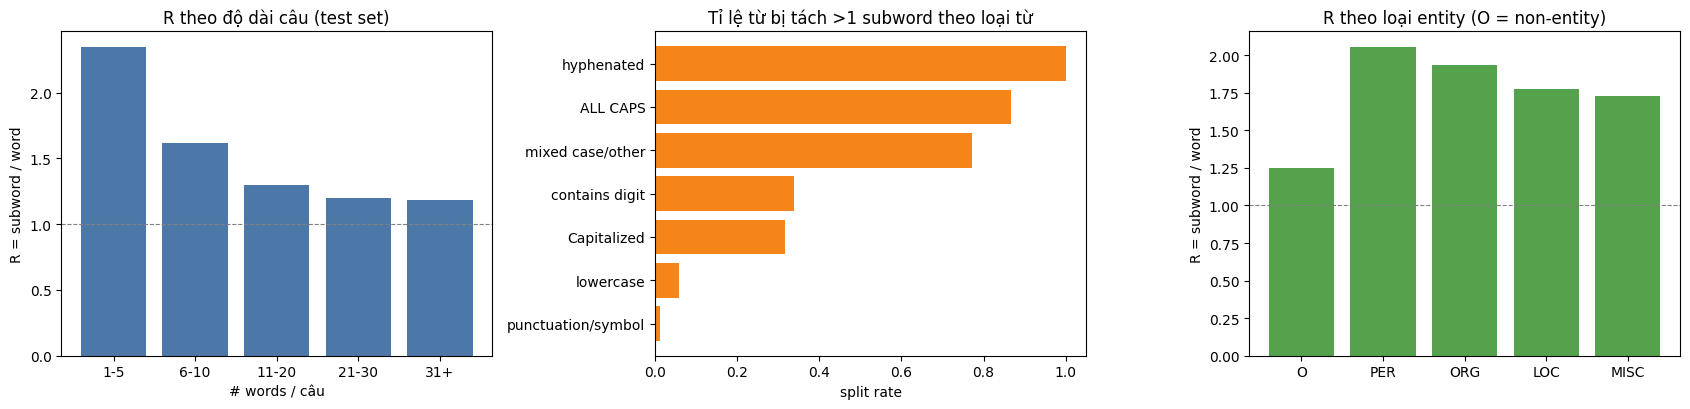

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))

axes[0].bar(by_len.index.astype(str), by_len["R_pooled"], color="#4C78A8")
axes[0].set_title("R theo độ dài câu (test set)"); axes[0].set_xlabel("# words / câu"); axes[0].set_ylabel("R = subword / word")
axes[0].axhline(1.0, color="gray", lw=0.8, ls="--")

ct = cat_tab.sort_values("split_rate")
axes[1].barh(ct.index, ct["split_rate"], color="#F58518")
axes[1].set_title("Tỉ lệ từ bị tách >1 subword theo loại từ"); axes[1].set_xlabel("split rate")

et = summarize(wall, "etype").reindex(["O", "PER", "ORG", "LOC", "MISC"])
axes[2].bar(et.index, et["R"], color="#54A24B")
axes[2].set_title("R theo loại entity (O = non-entity)"); axes[2].set_ylabel("R = subword / word")
axes[2].axhline(1.0, color="gray", lw=0.8, ls="--")

plt.tight_layout(); plt.show()

In [19]:
def alignment_stats(sents, labels, strategy, max_length=128, batch_size=512):
    c = Counter(); lab_cnt = Counter()
    for start in range(0, len(sents), batch_size):
        batch = sents[start:start + batch_size]
        enc = tokenizer(batch, is_split_into_words=True, truncation=True, max_length=max_length)
        for b in range(len(batch)):
            wids = enc.word_ids(b)
            tl = align_labels(wids, labels[start + b], strategy)
            prev = None
            for wid, y in zip(wids, tl):
                c["total_tokens"] += 1
                if wid is None:
                    c["special"] += 1
                elif wid == prev:
                    c["continuation_subwords"] += 1
                prev = wid if wid is not None else prev
                if y != IGNORE_INDEX:
                    c["tokens_in_loss"] += 1
                    lab_cnt[ID2LABEL[y]] += 1
    return c, lab_cnt

cA, labA = alignment_stats(test_w, test_l, "A")
cB, labB = alignment_stats(test_w, test_l, "B")
cmp_df = pd.DataFrame({"Strategy A": cA, "Strategy B": cB}).T
cmp_df["% tokens trong loss"] = (cmp_df["tokens_in_loss"] / cmp_df["total_tokens"] * 100).round(2)
display(cmp_df)

lab_df = pd.DataFrame({"Strategy A": labA, "Strategy B": labB}).reindex(LABEL_NAMES).fillna(0).astype(int)
lab_df["B - A"] = lab_df["Strategy B"] - lab_df["Strategy A"]
print("Phân bố nhãn tham gia loss:")
display(lab_df)

,total_tokens,special,tokens_in_loss,continuation_subwords,% tokens trong loss
Strategy A,70344,6906,46417,17021,65.99
Strategy B,70344,6906,63438,17021,90.18


Phân bố nhãn tham gia loss:


,Strategy A,Strategy B,B - A
O,38312,47914,9602
B-PER,1615,1615,0
I-PER,1154,4075,2921
B-ORG,1661,1661,0
I-ORG,835,3172,2337
B-LOC,1666,1666,0
I-LOC,256,1747,1491
B-MISC,702,702,0
I-MISC,216,886,670


Những loại từ nào thường bị chia thành nhiều subword? 

Từ có dấu gạch nối (hyphenated): Tỉ lệ bị tách cao nhất (xấp xỉ 100%) do tokenizer tách riêng dấu gạch nối và các từ thành phần.   

Từ viết hoa toàn bộ (ALL CAPS) và viết hoa xen kẽ (mixed case): Tỉ lệ bị tách rất cao (khoảng 77% - 87%) vì thường là từ viết tắt, mã hiệu hoặc tên thương hiệu không có sẵn nguyên từ trong từ vựng.   

Thực thể có tên (PER, ORG, LOC, MISC) và từ viết hoa chữ cái đầu (Capitalized): Các tên riêng, từ hiếm có chỉ số R cao (1,73 - 2,06 subword/từ), vượt trội so với từ thông thường ngoài thực thể (nhãn O chỉ khoảng 1,25).   

Từ chứa chữ số (contains digit): Các chuỗi kết hợp chữ và số thường bị chia nhỏ thành nhiều phần (tỉ lệ tách khoảng 34%).   

Từ mang hậu tố biến thể: Thường bị tách thành phần gốc từ và phụ tố (ví dụ: playing bị tách thành play và ##ing).  